In [ ]:
## Compre ESCO_coverage_by-programme with demand_by_programme

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / "data/processed").exists():
    ROOT = ROOT.parent

DATA = ROOT / "data" / "processed"

esco_coverage = pd.read_csv(DATA / "ESCO_coverage_by_programme.csv")
demand = pd.read_csv(DATA / "demand_by_programme.csv")


### Coverage of searchable ESCO profile skills in job postings

For each programme, this chart shows the share of searchable skills in its mapped ESCO occupation profile that were found at least once in job-posting texts. Labels show the number detected out of the searchable profile skills and the percentage. This is coverage of the searchable ESCO reference set—not the share of postings mentioning skills. Exact-text matching may miss paraphrases.

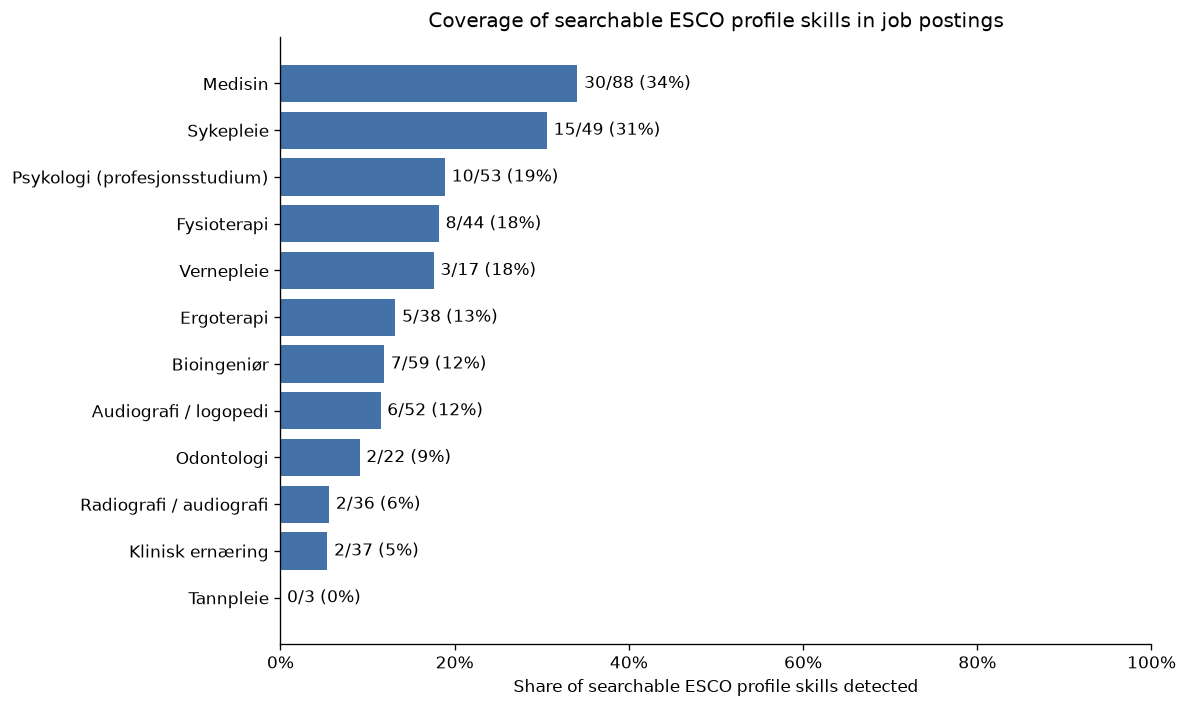

In [21]:
from matplotlib.ticker import PercentFormatter

plot_data = esco_coverage.sort_values("share_searchable_mentioned")

labels = [
    f"{int(mentioned)}/{int(searchable)} ({share:.0%})"
    for mentioned, searchable, share in zip(
        plot_data["profile_skills_mentioned"],
        plot_data["profile_skills_searchable"],
        plot_data["share_searchable_mentioned"],
    )
]

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(
    plot_data["programme"],
    plot_data["share_searchable_mentioned"],
    color="#4472A8",
)

ax.bar_label(bars, labels=labels, padding=4)
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.set_xlim(0, 1)
ax.set_title("Coverage of searchable ESCO profile skills in job postings")
ax.set_xlabel("Share of searchable ESCO profile skills detected")
ax.set_ylabel("")

fig.tight_layout()
plt.show()